**Reproduction of the Base Paper Results**

In [ ]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 81.1 MB/s eta 0:00:00


In [ ]:
# libraries to install
import sys, numpy, pandas, scipy, sklearn, skimage, PIL, pydicom, torch, torchvision, timm
print("python", sys.version.split()[0])
for m in [numpy, pandas, scipy, sklearn, skimage, PIL, pydicom, torch, torchvision, timm]:
    print(m.__name__, m.__version__)

python 3.13.15
numpy 2.1.3
pandas 2.2.3
scipy 1.16.3
sklearn 1.6.1
skimage 0.25.2
PIL 11.3.0
pydicom 2.4.4
torch 2.11.0+cu128
torchvision 0.26.0+cu128
timm 1.0.29


In [ ]:
#step 1c: Unzip the data and set paths
from google.colab import drive; drive.mount('/content/drive')
!mkdir -p /content/lss_data
!unzip -q "/content/drive/MyDrive/LSS MRI AISSLab Dataset_V0.2.zip" -d /content/lss_data
import os
os.environ["LSS_PROJECT"] = "/content/lss_data"
os.environ["LSS_STUDY"]   = "/content/drive/MyDrive/lss_study"   # outputs survive Colab resets

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# verify mount
import os, glob, subprocess
root = "/content/lss_data"
for z in glob.glob(f"{root}/**/*.zip", recursive=True):          # 1) nested zips
    print("unzipping nested:", z)
    subprocess.run(["unzip", "-q", "-o", z, "-d", os.path.dirname(z)])
cands = [os.path.dirname(p) for p in glob.glob(f"{root}/**/Foramina_Detection", recursive=True)]
print("dataset folder:", cands)                                    # 2) find by contents
link = f"{root}/LSS MRI AISSLab Dataset Medical Spine Sagittal MRI/LSS MRI AISSLab Dataset_V0.2"
if cands and not os.path.exists(link):
    os.symlink(cands[0], link)                                     # 3) link where code expects
print("link ok:", os.path.exists(link))
!du -sh /content/lss_data
!find /content/lss_data -maxdepth 3 | head -30

dataset folder: ['/content/lss_data']
link ok: True
3.5G	/content/lss_data
/content/lss_data
/content/lss_data/DICOM
/content/lss_data/DICOM/0131
/content/lss_data/DICOM/0131/IM000010.dcm
/content/lss_data/DICOM/0131/IM000005.dcm
/content/lss_data/DICOM/0131/IM000011.dcm
/content/lss_data/DICOM/0131/IM000007.dcm
/content/lss_data/DICOM/0131/IM000000.dcm
/content/lss_data/DICOM/0131/IM000008.dcm
/content/lss_data/DICOM/0131/IM000004.dcm
/content/lss_data/DICOM/0131/IM000003.dcm
/content/lss_data/DICOM/0131/IM000002.dcm
/content/lss_data/DICOM/0131/IM000001.dcm
/content/lss_data/DICOM/0131/IM000006.dcm
/content/lss_data/DICOM/0131/IM000009.dcm
/content/lss_data/DICOM/0258
/content/lss_data/DICOM/0258/IM000010.dcm
/content/lss_data/DICOM/0258/IM000012.dcm
/content/lss_data/DICOM/0258/IM000005.dcm
/content/lss_data/DICOM/0258/IM000011.dcm
/content/lss_data/DICOM/0258/IM000007.dcm
/content/lss_data/DICOM/0258/IM000000.dcm
/content/lss_data/DICOM/0258/IM000008.dcm
/content/lss_data/DICOM/025

In [ ]:
import os
old_outer = "/content/lss_data/LSS MRI AISSLab Dataset Medical Spine Sagittal MRI"
old_link  = old_outer + "/LSS MRI AISSLab Dataset_V0.2"
if os.path.islink(old_link): os.unlink(old_link)                      # remove the loop
if os.path.isdir(old_outer) and not os.listdir(old_outer): os.rmdir(old_outer)
outer = "/content/lss_project/LSS MRI AISSLab Dataset Medical Spine Sagittal MRI"
os.makedirs(outer, exist_ok=True)
link = outer + "/LSS MRI AISSLab Dataset_V0.2"
if not os.path.exists(link): os.symlink("/content/lss_data", link)    # clean link
os.environ["LSS_PROJECT"] = "/content/lss_project"
os.environ["LSS_STUDY"]   = "/content/drive/MyDrive/lss_study"
print("loop removed:", not os.path.exists(old_link), "| new link:", os.path.exists(link))

loop removed: True | new link: True


In [ ]:
# RUN THIS CODE BEFORE EACH SESSION
import os, subprocess
from google.colab import drive
drive.mount('/content/drive')
REPO = "/content/LSS_foraminal_stenosis_imaging"
ZIP  = "/content/drive/MyDrive/LSS MRI AISSLab Dataset_V0.2.zip"   # your zip's exact path
DATA = "/content/lss_data"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "-q", "https://github.com/rohanpa27/LSS_foraminal_stenosis_imaging.git", REPO])
subprocess.run(["pip", "install", "-q", "pydicom==2.4.4"])
if not os.path.isdir(f"{DATA}/DICOM"):
    os.makedirs(DATA, exist_ok=True)
    subprocess.run(["unzip", "-q", "-o", ZIP, "-d", DATA])        # a few minutes for 3.5 GB
outer = "/content/lss_project/LSS MRI AISSLab Dataset Medical Spine Sagittal MRI"
os.makedirs(outer, exist_ok=True)
link = outer + "/LSS MRI AISSLab Dataset_V0.2"
if not os.path.islink(link): os.symlink(DATA, link)
os.environ["LSS_PROJECT"] = "/content/lss_project"
os.environ["LSS_STUDY"]   = "/content/drive/MyDrive/lss_study"
os.chdir(REPO)
print("repo:", os.path.isdir(REPO), "| DICOM:", os.path.isdir(f"{DATA}/DICOM"), "| cwd:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
repo: True | DICOM: True | cwd: /content/LSS_foraminal_stenosis_imaging


In [ ]:
#checkpoint
import sys, importlib, pandas as pd, torch
sys.path.insert(0, "/content/LSS_foraminal_stenosis_imaging/src")
import config as C; importlib.reload(C)
for p in [C.DICOM_DIR, C.DET_DIR, C.SEG_MASK_DIR, C.SEG_MID_DIR]:
    print(p.exists(), p)
print("DICOM patient folders:", len(list(C.DICOM_DIR.iterdir())))
print(pd.read_csv("/content/LSS_foraminal_stenosis_imaging/data/splits.csv", dtype=str).split.value_counts().to_dict())
print("GPU:", torch.cuda.is_available())

True /content/lss_project/LSS MRI AISSLab Dataset Medical Spine Sagittal MRI/LSS MRI AISSLab Dataset_V0.2/DICOM
True /content/lss_project/LSS MRI AISSLab Dataset Medical Spine Sagittal MRI/LSS MRI AISSLab Dataset_V0.2/Foramina_Detection
True /content/lss_project/LSS MRI AISSLab Dataset Medical Spine Sagittal MRI/LSS MRI AISSLab Dataset_V0.2/Segmentation/Masks
True /content/lss_project/LSS MRI AISSLab Dataset Medical Spine Sagittal MRI/LSS MRI AISSLab Dataset_V0.2/Segmentation/Middle_Slice
DICOM patient folders: 500
{'test': 94, 'fold0': 75, 'fold1': 75, 'fold2': 75, 'fold3': 75, 'fold4': 75}
GPU: True


**Part 1:Pipeline: Data Preperation**

*   **parse_annotations.py** reads every foramen bounding box and grade, plus the pixel spacing and scanner vendor from the DICOM headers.
*   **morphometry.py** computes the ten millimetre measurements from the mid-sagittal masks.
*   **build_dataset.py** joins the two into one table, master.csv.
*   **splits.py** creates the patient-level train/test split.






In [ ]:
# source
%cd /content/LSS_foraminal_stenosis_imaging/src

/content/LSS_foraminal_stenosis_imaging/src


In [ ]:
# annotations
!python parse_annotations.py

Wrote /content/drive/MyDrive/lss_study/data/cache/foramina.csv  (2979 foramina, 469 patients)
Grade distribution: {0: 2009, 1: 508, 2: 254, 3: 208}
Vendor distribution: {'Philips': 1928, 'GE': 1051}
PixelSpacing missing: 2


In [ ]:
#morphometry file
!python morphometry.py

Wrote /content/drive/MyDrive/lss_study/data/cache/morphometry.csv  (2449 patient-levels, 500 patients)
       disc_height_mm  disc_vb_ratio  listhesis_mm  seg_angle_deg  postA_dist_mm
level                                                                           
L1-L2           10.10           0.51          7.24           6.24          75.88
L2-L3           10.64           0.51          5.21           6.28          67.01
L3-L4           11.14           0.52          1.08           8.70          70.74
L4-L5           11.31           0.55         -4.92          14.97          85.51
L5-S1           11.13           0.54           NaN            NaN         104.01


In [ ]:
# build dataset
!python build_dataset.py

master.csv: 2979 foramina; disc-height morphometry coverage = 98.5%
Missing per feature: {'disc_height_mm': 44, 'disc_vb_ratio': 44, 'vb_upper_mm': 44, 'vb_lower_mm': 315, 'listhesis_mm': 315, 'listhesis_ratio': 315, 'seg_angle_deg': 315, 'disc_width_mm': 44, 'postA_dist_mm': 44, 'postB_dist_mm': 44}

=== Feature means by grade (Normal->Severe) + Spearman rho with grade ===
  disc_height_mm   N=11.179  Mi=11.333  Mo=11.18  Sv=11.139   rho=+0.021 (p=2.5e-01)
  disc_vb_ratio    N=0.534  Mi=0.539  Mo=0.534  Sv=0.544   rho=+0.026 (p=1.5e-01)
  vb_upper_mm      N=20.802  Mi=21.218  Mo=21.274  Sv=20.808   rho=+0.074 (p=5.5e-05)
  vb_lower_mm      N=21.269  Mi=20.942  Mo=20.68  Sv=20.332   rho=-0.129 (p=2.5e-11)
  listhesis_mm     N=3.149  Mi=-0.488  Mo=-1.576  Sv=-1.841   rho=-0.349 (p=3.5e-77)
  listhesis_ratio  N=0.078  Mi=-0.013  Mo=-0.041  Sv=-0.043   rho=-0.355 (p=6.8e-80)
  seg_angle_deg    N=8.065  Mi=10.628  Mo=10.629  Sv=11.433   rho=+0.211 (p=3.9e-28)
  disc_width_mm    N=41.204  M

In [ ]:
#split dataset
!python splits.py

Patients: 469  (test=94, dev=375)

Foramen-level grade counts per split:
grade    0    1   2   3
split                  
fold0  336   85  52  33
fold1  324   79  33  33
fold2  312   74  44  32
fold3  351   85  34  34
fold4  308   81  38  31
test   378  104  53  45

Total foramina: test=580, dev=2399


In [ ]:
#Matching the split.csv with paper's split.csv
import pandas as pd, shutil
paper_f = "/content/LSS_foraminal_stenosis_imaging/data/splits.csv"
mine  = pd.read_csv(C.CACHE / "splits.csv", dtype=str).set_index("patient").split.sort_index()
paper = pd.read_csv(paper_f, dtype=str).set_index("patient").split.sort_index()
same = mine.equals(paper)
print("identical to paper's split:", same)
if not same:
    shutil.copy(paper_f, C.CACHE / "splits.csv"); print("replaced with the paper's exact split")

identical to paper's split: True


**Part 2: Region of Interest (ROI) Extraction**

In [ ]:
# a) Extracts the crops from src
%cd /content/LSS_foraminal_stenosis_imaging/src

/content/LSS_foraminal_stenosis_imaging/src


In [ ]:
# crops
!python extract_rois.py

ROI crops: 2978 written, 1 failed -> /content/drive/MyDrive/lss_study/data/cache/rois
ROI cache size: 49.6 MB


2978 crops | 468 patients


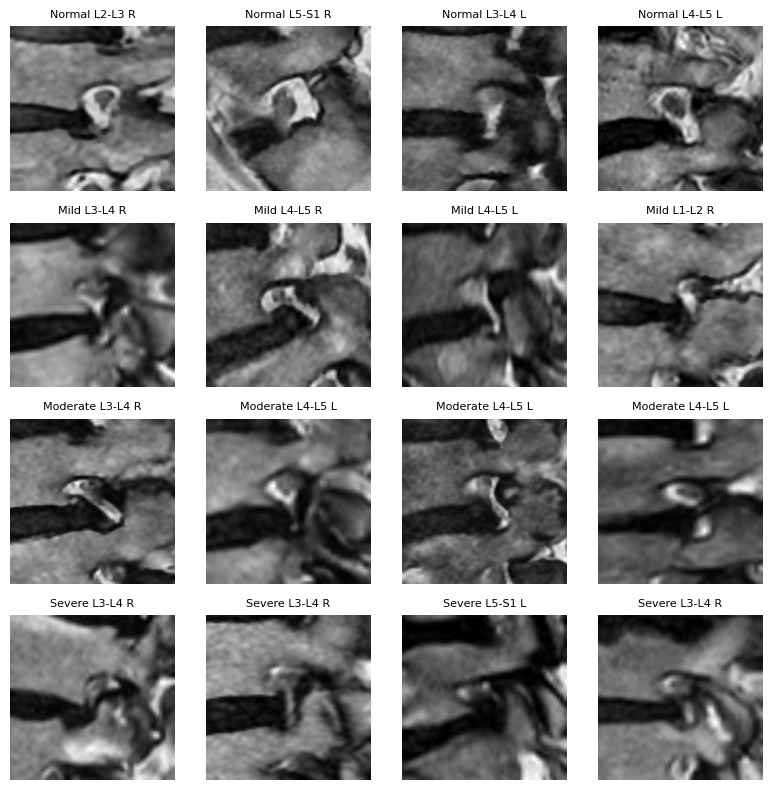

In [ ]:
# b) check the count and look at samples, 4 per grade
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
m, idx = pd.read_csv(C.CACHE/"master.csv"), pd.read_csv(C.CACHE/"roi_index.csv")
d = m.merge(idx, on="foramen_id")
print(len(idx), "crops |", d.patient.nunique(), "patients")
fig, ax = plt.subplots(4, 4, figsize=(8, 8))
for g in range(4):
    for j, r in enumerate(d[d.grade == g].sample(4, random_state=0).itertuples()):
        ax[g, j].imshow(Image.open(r.roi_path), cmap="gray"); ax[g, j].axis("off")
        ax[g, j].set_title(f"{C.GRADES[g]} {r.level} {r.side}", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Lightweight Smoked test to run code and to save GPU time
import os, subprocess
from google.colab import drive
drive.mount('/content/drive')
REPO = "/content/LSS_foraminal_stenosis_imaging"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "-q", "https://github.com/rohanpa27/LSS_foraminal_stenosis_imaging.git", REPO])
subprocess.run(["pip", "install", "-q", "pydicom==2.4.4", "timm"])
os.environ["LSS_PROJECT"] = "/content/lss_project"
os.environ["LSS_STUDY"]   = "/content/drive/MyDrive/lss_study"
os.chdir(f"{REPO}/src")
import torch; print("GPU:", torch.cuda.is_available(), "| cwd:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: True | cwd: /content/LSS_foraminal_stenosis_imaging/src


In [ ]:
#Smoke test. 1 Fold 3 epochs
!python train2.py --config appearance --folds 0 --seeds 1337 --tag smoke --backbone resnet18 --img-size 224 --epochs 3 --patience 3

device=cuda tag=smoke configs=['appearance'] folds=[0] seeds=[1337]
recipe={"anat_hidden": 64, "anat_out": 32, "backbone": "resnet18", "bright": 0.2, "bs": 48, "clip": 1.0, "contrast": 0.2, "drop": 0.3, "drop_path": 0.0, "ema": 0.995, "epochs": 3, "erase_p": 0.25, "freeze_blocks": 0, "img_size": 224, "loss_w": "none", "lr_backbone": 0.0002, "lr_head": 0.001, "n_tta": 4, "noise": 0.0, "patience": 3, "roi_dir": "rois", "rot_deg": 10.0, "sampler": "balanced", "scale": 0.1, "smooth": 0.0, "trans": 0.05, "warmup": 3, "wd": 0.0001}
n=2978 (dev=2398, test=580)
  RoiBank[rois] torch.Size([2978, 224, 224]) 149 MB
    [appearance] fold0 seed1337 exists, skip
DONE tag=smoke in 0s


In [ ]:
# longer smoke test to check QWK greater>0 value
!python train2.py --config appearance --folds 0 --seeds 1337 --tag smoke2 --backbone resnet18 --img-size 224 --epochs 12 --patience 12

device=cuda tag=smoke2 configs=['appearance'] folds=[0] seeds=[1337]
recipe={"anat_hidden": 64, "anat_out": 32, "backbone": "resnet18", "bright": 0.2, "bs": 48, "clip": 1.0, "contrast": 0.2, "drop": 0.3, "drop_path": 0.0, "ema": 0.995, "epochs": 12, "erase_p": 0.25, "freeze_blocks": 0, "img_size": 224, "loss_w": "none", "lr_backbone": 0.0002, "lr_head": 0.001, "n_tta": 4, "noise": 0.0, "patience": 12, "roi_dir": "rois", "rot_deg": 10.0, "sampler": "balanced", "scale": 0.1, "smooth": 0.0, "trans": 0.05, "warmup": 3, "wd": 0.0001}
n=2978 (dev=2398, test=580)
  RoiBank[rois] torch.Size([2978, 224, 224]) 149 MB
    [appearance] fold0 seed1337  val_QWK=0.2853 (ep12)  +TTA=0.2732
DONE tag=smoke2 in 78s


In [ ]:
#predictions of smoke test 2
import sys, numpy as np; sys.path.insert(0, "."); import config as C
z = np.load(C.OUT / "runs" / "smoke2" / "appearance_f0_s1337.npz", allow_pickle=True)
print("true grades :", np.bincount(z["val_y"], minlength=4))
print("predicted   :", np.bincount(z["val_P"].argmax(1), minlength=4))

true grades : [336  85  52  33]
predicted   : [399  93  14   0]


In [ ]:
#check to QWK score after the predictions done
# This is paper reported result started
from sklearn.metrics import cohen_kappa_score, confusion_matrix
y, p = z["val_y"], z["val_P"].argmax(1)
print("QWK:", round(cohen_kappa_score(y, p, weights="quadratic"), 3))
print(confusion_matrix(y, p, labels=[0, 1, 2, 3]))

QWK: 0.273
[[305  30   1   0]
 [ 47  36   2   0]
 [ 23  22   7   0]
 [ 24   5   4   0]]


In [ ]:
# Step5: fusion configuration, folds 0 and 1, one seed, full schedule - train at 224px
!python train2.py --config fusion --folds 0,1 --seeds 1337 --tag sel_r18_224 --backbone resnet18 --img-size 224 --bs 32 --n-tta 1


device=cuda tag=sel_r18_224 configs=['fusion'] folds=[0, 1] seeds=[1337]
recipe={"anat_hidden": 64, "anat_out": 32, "backbone": "resnet18", "bright": 0.2, "bs": 32, "clip": 1.0, "contrast": 0.2, "drop": 0.3, "drop_path": 0.0, "ema": 0.995, "epochs": 60, "erase_p": 0.25, "freeze_blocks": 0, "img_size": 224, "loss_w": "none", "lr_backbone": 0.0002, "lr_head": 0.001, "n_tta": 1, "noise": 0.0, "patience": 14, "roi_dir": "rois", "rot_deg": 10.0, "sampler": "balanced", "scale": 0.1, "smooth": 0.0, "trans": 0.05, "warmup": 3, "wd": 0.0001}
n=2978 (dev=2398, test=580)
  RoiBank[rois] torch.Size([2978, 224, 224]) 149 MB
    [fusion] fold0 seed1337 exists, skip
    [fusion] fold1 seed1337 exists, skip
DONE tag=sel_r18_224 in 0s


In [ ]:
#show the previously stored values
!python train2.py --config fusion --folds 0,1 --seeds 1337 --tag sel_r18_224_rerun --backbone resnet18 --img-size 224 --bs 32 --n-tta 1

device=cuda tag=sel_r18_224_rerun configs=['fusion'] folds=[0, 1] seeds=[1337]
recipe={"anat_hidden": 64, "anat_out": 32, "backbone": "resnet18", "bright": 0.2, "bs": 32, "clip": 1.0, "contrast": 0.2, "drop": 0.3, "drop_path": 0.0, "ema": 0.995, "epochs": 60, "erase_p": 0.25, "freeze_blocks": 0, "img_size": 224, "loss_w": "none", "lr_backbone": 0.0002, "lr_head": 0.001, "n_tta": 1, "noise": 0.0, "patience": 14, "roi_dir": "rois", "rot_deg": 10.0, "sampler": "balanced", "scale": 0.1, "smooth": 0.0, "trans": 0.05, "warmup": 3, "wd": 0.0001}
n=2978 (dev=2398, test=580)
  RoiBank[rois] torch.Size([2978, 224, 224]) 149 MB

model.safetensors: downloading bytes:   0% 0.00/46.8M [00:00<?, ?B/s]
model.safetensors: downloading bytes:  15% 7.03M/46.8M [00:00<00:01, 21.8MB/s]
model.safetensors: downloading bytes:  48% 22.4M/46.8M [00:00<00:00, 44.2MB/s, 1.50MB/s  ]
model.safetensors: downloading bytes:  68% 31.8M/46.8M [00:00<00:00, 59.2MB/s, 2.18MB/s  ]
model.safetensors: downloading bytes: 100% 

In [ ]:
# Step 5 C:Train at 128 px:
!python train2.py --config fusion --folds 0,1 --seeds 1337 --tag sel_r18_128 --backbone resnet18 --img-size 128 --bs 48 --n-tta 1

device=cuda tag=sel_r18_128 configs=['fusion'] folds=[0, 1] seeds=[1337]
recipe={"anat_hidden": 64, "anat_out": 32, "backbone": "resnet18", "bright": 0.2, "bs": 48, "clip": 1.0, "contrast": 0.2, "drop": 0.3, "drop_path": 0.0, "ema": 0.995, "epochs": 60, "erase_p": 0.25, "freeze_blocks": 0, "img_size": 128, "loss_w": "none", "lr_backbone": 0.0002, "lr_head": 0.001, "n_tta": 1, "noise": 0.0, "patience": 14, "roi_dir": "rois", "rot_deg": 10.0, "sampler": "balanced", "scale": 0.1, "smooth": 0.0, "trans": 0.05, "warmup": 3, "wd": 0.0001}
n=2978 (dev=2398, test=580)
  RoiBank[rois] torch.Size([2978, 224, 224]) 149 MB
  cache 224px -> resampled on-device to img_size=128
    [fusion] fold0 seed1337 exists, skip
    [fusion] fold1 seed1337 exists, skip
DONE tag=sel_r18_128 in 0s


In [ ]:
#comparing the above tw0 128px and 224px results
import sys, glob, numpy as np; sys.path.insert(0, "."); import config as C
from sklearn.metrics import cohen_kappa_score as ck
for tag in ["sel_r18_224", "sel_r18_128"]:
    ks = [ck(np.load(f)["val_y"], np.load(f)["val_P"].argmax(1), weights="quadratic")
          for f in sorted(glob.glob(str(C.OUT / "runs" / tag / "fusion_f*_s1337.npz")))]
    print(tag, [round(k, 3) for k in ks], "mean", round(float(np.mean(ks)), 3))

sel_r18_224 [np.float64(0.747), np.float64(0.805)] mean 0.776
sel_r18_128 [np.float64(0.749), np.float64(0.802)] mean 0.775


**Final Training Compaign**

In [ ]:
# Paper mentions multiseeds, but we use 3 seeds (1337, 1338, 1339) here
import sys, json; sys.path.insert(0, "."); import config as C
best = C.OUT / "runs" / "best.json"
json.dump({"name": "r18_128", "recipe": {"backbone": "resnet18", "img_size": 128, "bs": 48,
           "n_tta": 1, "roi_dir": "rois", "epochs": 60, "patience": 14}}, open(best, "w"), indent=1)
print("saved:", best)


saved: /content/drive/MyDrive/lss_study/outputs/runs/best.json


In [ ]:
#cofig fusion
!python campaign.py --recipe-json "{best}" --tag final --configs fusion --folds 0,1,2,3,4 --seeds 1337,1338,1339

=== campaign stage=None tag=final device=cuda configs=['fusion'] folds=[0, 1, 2, 3, 4] seeds=[1337, 1338, 1339] epochs=30 ===
  -> recipe r18_128: {"backbone": "resnet18", "bs": 48, "epochs": 60, "img_size": 128, "n_tta": 1, "patience": 14, "roi_dir": "rois"}
  RoiBank[rois] torch.Size([2978, 224, 224]) 149 MB
    [r18_128/fusion] f0 s1337 cached val_tta=0.7472
    [r18_128/fusion] f1 s1337 cached val_tta=0.8132
    [r18_128/fusion] f2 s1337 cached val_tta=0.7500
    [r18_128/fusion] f3 s1337 cached val_tta=0.7872
    [r18_128/fusion] f4 s1337 cached val_tta=0.7627
    [r18_128/fusion] f0 s1338 cached val_tta=0.7682
    [r18_128/fusion] f1 s1338 cached val_tta=0.7910
    [fusion] fold2 seed1338  val_QWK=0.7434 (ep26)  +TTA=0.7434
    [fusion] fold3 seed1338  val_QWK=0.7928 (ep46)  +TTA=0.7928
    [fusion] fold4 seed1338  val_QWK=0.7954 (ep30)  +TTA=0.7954
    [fusion] fold0 seed1339  val_QWK=0.7516 (ep44)  +TTA=0.7516
    [fusion] fold1 seed1339  val_QWK=0.7907 (ep41)  +TTA=0.7907
    

In [ ]:
# Config appreance run
!python campaign.py --recipe-json "{best}" --tag final --configs appearance --folds 0,1,2,3,4 --seeds 1337,1338,1339

=== campaign stage=None tag=final device=cuda configs=['appearance'] folds=[0, 1, 2, 3, 4] seeds=[1337, 1338, 1339] epochs=30 ===
  -> recipe r18_128: {"backbone": "resnet18", "bs": 48, "epochs": 60, "img_size": 128, "n_tta": 1, "patience": 14, "roi_dir": "rois"}
  RoiBank[rois] torch.Size([2978, 224, 224]) 149 MB
    [appearance] fold0 seed1337  val_QWK=0.7305 (ep23)  +TTA=0.7305
    [appearance] fold1 seed1337  val_QWK=0.8160 (ep33)  +TTA=0.8160
    [appearance] fold2 seed1337  val_QWK=0.7426 (ep36)  +TTA=0.7426
    [appearance] fold3 seed1337  val_QWK=0.7960 (ep40)  +TTA=0.7960
    [appearance] fold4 seed1337  val_QWK=0.7680 (ep55)  +TTA=0.7680
    [appearance] fold0 seed1338  val_QWK=0.7519 (ep31)  +TTA=0.7519
    [appearance] fold1 seed1338  val_QWK=0.7965 (ep39)  +TTA=0.7965
    [appearance] fold2 seed1338  val_QWK=0.7344 (ep36)  +TTA=0.7344
    [appearance] fold3 seed1338  val_QWK=0.7900 (ep31)  +TTA=0.7900
    [appearance] fold4 seed1338  val_QWK=0.7677 (ep33)  +TTA=0.7677
    

In [ ]:
# config nominal seed run here
!python campaign.py --recipe-json "{best}" --tag final --configs nominal --folds 0,1,2,3,4 --seeds 1337,1338,1339

=== campaign stage=None tag=final device=cuda configs=['nominal'] folds=[0, 1, 2, 3, 4] seeds=[1337, 1338, 1339] epochs=30 ===
  -> recipe r18_128: {"backbone": "resnet18", "bs": 48, "epochs": 60, "img_size": 128, "n_tta": 1, "patience": 14, "roi_dir": "rois"}
  RoiBank[rois] torch.Size([2978, 224, 224]) 149 MB

model.safetensors: downloading bytes:   0% 0.00/46.8M [00:00<?, ?B/s]
model.safetensors: downloading bytes:  18% 8.61M/46.8M [00:00<00:01, 20.4MB/s]
model.safetensors: downloading bytes:  28% 13.1M/46.8M [00:00<00:01, 26.5MB/s,  854kB/s  ]
model.safetensors: downloading bytes:  41% 19.4M/46.8M [00:00<00:00, 36.0MB/s, 1.29MB/s  ]
model.safetensors: downloading bytes:  67% 31.4M/46.8M [00:00<00:00, 59.0MB/s, 1.90MB/s  ]
model.safetensors: downloading bytes: 100% 44.0M/44.0M [00:00<00:00, 51.7MB/s, 4.25MB/s  ]
model.safetensors: reconstructing file: 100% 46.8M/46.8M [00:00<00:00, 55.1MB/s, 4.55MB/s  ]
    [nominal] fold0 seed1337  val_QWK=0.7279 (ep47)  +TTA=0.7279
    [nominal] f

In [ ]:
# checkpoints of above 3 foleds
import glob
for cfg in ["fusion", "appearance", "nominal"]:
    n = len(glob.glob(str(C.OUT / "runs" / "final" / f"*__{cfg}_f*_s*.npz")))
    print(f"{cfg:<11} {n} / 15 runs")

fusion      15 / 15 runs
appearance  15 / 15 runs
nominal     15 / 15 runs


**Step 7: Ensemble and test-set evaluation (CPU only)**

In [1]:
# RESTART EVERYTHING AND RUN NEXT STEPS
import os, sys, subprocess
from google.colab import drive
drive.mount('/content/drive')
REPO = "/content/LSS_foraminal_stenosis_imaging"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "-q", "https://github.com/rohanpa27/LSS_foraminal_stenosis_imaging.git", REPO])
subprocess.run(["pip", "install", "-q", "pydicom==2.4.4", "timm"])
os.environ["LSS_PROJECT"] = "/content/lss_project"
os.environ["LSS_STUDY"]   = "/content/drive/MyDrive/lss_study"
os.chdir(f"{REPO}/src"); sys.path.insert(0, f"{REPO}/src")
import config as C
print("cwd:", os.getcwd(), "| runs:", len(list((C.OUT / "runs" / "final").glob("*.npz"))), "npz files")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cwd: /content/LSS_foraminal_stenosis_imaging/src | runs: 60 npz files


In [ ]:
#step 7: run this light setup cell
import sys; sys.path.insert(0, "."); import config as C

In [ ]:
# 7a: ensemble blind preview
!python ensemble.py --tag final --blind


[nominal] 15 models, folds [0, 1, 2, 3, 4], OOF n=2398, test n=580
      rule argmax      OOF(nested)=0.7615  OOF(in-sample)=0.7615
      rule expected    OOF(nested)=0.7845  OOF(in-sample)=0.7917 params=[0.66, 1.18, 2.18]
      rule cumulative  OOF(nested)=0.7683  OOF(in-sample)=0.7860 params=[0.68, 0.22, 0.38]
      chose 'expected' = simplest rule within 0.010 QWK of best (0.7845)
      -> rule=expected params=[0.66, 1.18, 2.18]
      -> OOF QWK=0.7845   [test split not read: --blind]

[appearance] 15 models, folds [0, 1, 2, 3, 4], OOF n=2398, test n=580
      rule argmax      OOF(nested)=0.7700  OOF(in-sample)=0.7700
      rule expected    OOF(nested)=0.7903  OOF(in-sample)=0.7991 params=[0.74, 1.24, 2.16]
      rule cumulative  OOF(nested)=0.7757  OOF(in-sample)=0.7910 params=[0.66, 0.28, 0.32]
      chose 'expected' = simplest rule within 0.010 QWK of best (0.7903)
      -> rule=expected params=[0.74, 1.24, 2.16]
      -> OOF QWK=0.7903   [test split not read: --blind]

[fusion]

In [ ]:
# 7b: unblind above to score the test set
!python ensemble.py --tag final --out "{C.METRICS}"


[nominal] 15 models, folds [0, 1, 2, 3, 4], OOF n=2398, test n=580
      rule argmax      OOF(nested)=0.7615  OOF(in-sample)=0.7615
      rule expected    OOF(nested)=0.7845  OOF(in-sample)=0.7917 params=[0.66, 1.18, 2.18]
      rule cumulative  OOF(nested)=0.7683  OOF(in-sample)=0.7860 params=[0.68, 0.22, 0.38]
      chose 'expected' = simplest rule within 0.010 QWK of best (0.7845)
      -> rule=expected params=[0.66, 1.18, 2.18]
      -> OOF QWK=0.7845   TEST QWK=0.8142  (test acc=0.7672)

[appearance] 15 models, folds [0, 1, 2, 3, 4], OOF n=2398, test n=580
      rule argmax      OOF(nested)=0.7700  OOF(in-sample)=0.7700
      rule expected    OOF(nested)=0.7903  OOF(in-sample)=0.7991 params=[0.74, 1.24, 2.16]
      rule cumulative  OOF(nested)=0.7757  OOF(in-sample)=0.7910 params=[0.66, 0.28, 0.32]
      chose 'expected' = simplest rule within 0.010 QWK of best (0.7903)
      -> rule=expected params=[0.74, 1.24, 2.16]
      -> OOF QWK=0.7903   TEST QWK=0.8213  (test acc=0.7638)



In [ ]:
#7c : full avaluation of the paper (reproduced)
!python evaluate.py

    config split    n   qwk  accuracy  balanced_acc  macro_f1  adjacent_acc  qwk_lo  qwk_hi
   nominal   oof 2398 0.784     0.747         0.579     0.580         0.969     NaN     NaN
   nominal  test  580 0.814     0.767         0.621     0.639         0.976   0.768   0.852
appearance   oof 2398 0.790     0.747         0.589     0.588         0.970     NaN     NaN
appearance  test  580 0.821     0.764         0.623     0.643         0.978   0.773   0.858
    fusion   oof 2398 0.789     0.749         0.571     0.584         0.976     NaN     NaN
    fusion  test  580 0.807     0.753         0.589     0.623         0.979   0.757   0.844

Boundary AUROC (test):
     config             boundary  auroc  n_pos
   nominal     Normal vs >=Mild  0.913    202
   nominal <=Mild vs >=Moderate  0.955     98
   nominal <=Moderate vs Severe  0.978     45
appearance     Normal vs >=Mild  0.920    202
appearance <=Mild vs >=Moderate  0.954     98
appearance <=Moderate vs Severe  0.979     45
    fusio

**Check for Deviation from Paper:**

***Sensitivity Analysis***

The paper's decision rule was argmax (pick the most likely grade). In my run, ensemble.py chose expected grade: argmax trailed by more than the 0.01 margin on validation data, so the same pre-set procedure picked a different rule. The procedure is identical; only the outcome differs.

In [ ]:
#Optional Check
#argmax sensitivity check here
!python ensemble.py --tag final --force-rule argmax --dry


[nominal] 15 models, folds [0, 1, 2, 3, 4], OOF n=2398, test n=580
      rule argmax      OOF(nested)=0.7615  OOF(in-sample)=0.7615
      rule expected    OOF(nested)=0.7845  OOF(in-sample)=0.7917 params=[0.66, 1.18, 2.18]
      rule cumulative  OOF(nested)=0.7683  OOF(in-sample)=0.7860 params=[0.68, 0.22, 0.38]
      chose 'expected' = simplest rule within 0.010 QWK of best (0.7845)
      -> rule=argmax params=None
      -> OOF QWK=0.7845   TEST QWK=0.8238  (test acc=0.7724)

[appearance] 15 models, folds [0, 1, 2, 3, 4], OOF n=2398, test n=580
      rule argmax      OOF(nested)=0.7700  OOF(in-sample)=0.7700
      rule expected    OOF(nested)=0.7903  OOF(in-sample)=0.7991 params=[0.74, 1.24, 2.16]
      rule cumulative  OOF(nested)=0.7757  OOF(in-sample)=0.7910 params=[0.66, 0.28, 0.32]
      chose 'expected' = simplest rule within 0.010 QWK of best (0.7903)
      -> rule=argmax params=None
      -> OOF QWK=0.7903   TEST QWK=0.8214  (test acc=0.7621)

[fusion] 15 models, folds [0, 1,

In [ ]:
#per-grade sensitivity and specificity, confusion matrix
import pandas as pd
print(pd.read_csv(C.FIGDATA / "per_grade_metrics.csv").to_string(index=False))
print(pd.read_csv(C.FIGDATA / "confusion_fusion.csv").to_string(index=False))

    config    grade   n  sensitivity  specificity
   nominal   Normal 378        0.910        0.752
   nominal     Mild 104        0.442        0.905
   nominal Moderate  53        0.509        0.932
   nominal   Severe  45        0.622        0.993
appearance   Normal 378        0.910        0.728
appearance     Mild 104        0.413        0.893
appearance Moderate  53        0.434        0.949
appearance   Severe  45        0.733        0.993
    fusion   Normal 378        0.905        0.723
    fusion     Mild 104        0.452        0.870
    fusion Moderate  53        0.377        0.954
    fusion   Severe  45        0.622        0.998
Unnamed: 0  Normal  Mild  Moderate  Severe
    Normal     342    33         3       0
      Mild      50    47         7       0
  Moderate       6    26        20       1
    Severe       0     3        14      28


In [ ]:
# 1. Back up the expected-grade results:
import shutil
for d in ["metrics", "tables"]:
    shutil.copytree(C.OUT / d, C.OUT / f"{d}_expected", dirs_exist_ok=True)

In [ ]:
# 2. Run with argmax forced:
!python ensemble.py --tag final --force-rule argmax --out "{C.METRICS}"
!python evaluate.py


[nominal] 15 models, folds [0, 1, 2, 3, 4], OOF n=2398, test n=580
      rule argmax      OOF(nested)=0.7615  OOF(in-sample)=0.7615
      rule expected    OOF(nested)=0.7845  OOF(in-sample)=0.7917 params=[0.66, 1.18, 2.18]
      rule cumulative  OOF(nested)=0.7683  OOF(in-sample)=0.7860 params=[0.68, 0.22, 0.38]
      chose 'expected' = simplest rule within 0.010 QWK of best (0.7845)
      -> rule=argmax params=None
      -> OOF QWK=0.7845   TEST QWK=0.8238  (test acc=0.7724)

[appearance] 15 models, folds [0, 1, 2, 3, 4], OOF n=2398, test n=580
      rule argmax      OOF(nested)=0.7700  OOF(in-sample)=0.7700
      rule expected    OOF(nested)=0.7903  OOF(in-sample)=0.7991 params=[0.74, 1.24, 2.16]
      rule cumulative  OOF(nested)=0.7757  OOF(in-sample)=0.7910 params=[0.66, 0.28, 0.32]
      chose 'expected' = simplest rule within 0.010 QWK of best (0.7903)
      -> rule=argmax params=None
      -> OOF QWK=0.7903   TEST QWK=0.8214  (test acc=0.7621)

[fusion] 15 models, folds [0, 1,

In [ ]:
# 3. Save the argmax set and restore expected-grade as the default:
for d in ["metrics", "tables"]:
    shutil.copytree(C.OUT / d, C.OUT / f"{d}_argmax", dirs_exist_ok=True)
    shutil.copytree(C.OUT / f"{d}_expected", C.OUT / d, dirs_exist_ok=True)

In [ ]:
# show argmax results from csv
import pandas as pd
A = C.OUT / "tables_argmax"
print(pd.read_csv(A / "per_grade_metrics.csv").query("config == 'fusion'").to_string(index=False))
print(pd.read_csv(A / "fusion_vs_appearance.csv").to_string(index=False))

config    grade   n  sensitivity  specificity
fusion   Normal 378        0.865        0.807
fusion     Mild 104        0.615        0.830
fusion Moderate  53        0.358        0.958
fusion   Severe  45        0.600        0.998
 delta_qwk  ci_lo  ci_hi  p_value
    -0.014 -0.042  0.008   0.2256


**8: Anatomy-only model and the level + side reference (CPU)**

authors' anatomy-only settings weren't published. Their code searches 12 small setups on validation folds 0–1, so we repeat that search and choose the winner the same way. These models use no images

In [ ]:
# 8a. Settings search.
!python campaign.py --stage anat --configs anatomy --tag anat_search

=== campaign stage=anat tag=anat_search device=cpu configs=['anatomy'] folds=[0, 1] seeds=[1337] epochs=30 ===
  -> recipe anat_h64o32_lr0.001_balanced: {"anat_hidden": 64, "anat_out": 32, "epochs": 200, "lr_head": 0.001, "patience": 30, "sampler": "balanced"}
    [anatomy] fold0 seed1337  val_QWK=0.3836 (ep10)  +TTA=0.3836
    [anatomy] fold1 seed1337  val_QWK=0.4324 (ep11)  +TTA=0.4324
  == anat_h64o32_lr0.001_balanced: mean val QWK 0.4080 (+TTA 0.4080) over 2 runs in 18s
  -> recipe anat_h64o32_lr0.001_sqrt: {"anat_hidden": 64, "anat_out": 32, "epochs": 200, "lr_head": 0.001, "patience": 30, "sampler": "sqrt"}
    [anatomy] fold0 seed1337  val_QWK=0.4396 (ep27)  +TTA=0.4396
    [anatomy] fold1 seed1337  val_QWK=0.4328 (ep17)  +TTA=0.4328
  == anat_h64o32_lr0.001_sqrt: mean val QWK 0.4362 (+TTA 0.4362) over 2 runs in 22s
  -> recipe anat_h64o32_lr0.003_balanced: {"anat_hidden": 64, "anat_out": 32, "epochs": 200, "lr_head": 0.003, "patience": 30, "sampler": "balanced"}
    [anatomy] f

In [ ]:
# 8b. Select the winner on validation QWK and save
import glob, re, json, numpy as np, collections
from sklearn.metrics import cohen_kappa_score as ck
sc = collections.defaultdict(list)
for f in glob.glob(str(C.OUT / "runs" / "anat_search" / "*__anatomy_f*_s1337.npz")):
    z = np.load(f); sc[f.split("/")[-1].split("__")[0]].append(ck(z["val_y"], z["val_P"].argmax(1), weights="quadratic"))
for k, v in sorted(sc.items(), key=lambda kv: -np.mean(kv[1])): print(f"{k:32s} {np.mean(v):.4f}")
best = max(sc, key=lambda k: np.mean(sc[k]))
h, o, lr, samp = re.match(r"anat_h(\d+)o(\d+)_lr([\d.e-]+)_(\w+)", best).groups()
anat_best = C.OUT / "runs" / "anat_best.json"
json.dump({"name": best, "recipe": dict(anat_hidden=int(h), anat_out=int(o), lr_head=float(lr),
           sampler=samp, epochs=200, patience=30)}, open(anat_best, "w"), indent=1)
print("selected:", best)

anat_h128o64_lr0.001_sqrt        0.4451
anat_h64o32_lr0.001_sqrt         0.4362
anat_h256o64_lr0.001_sqrt        0.4345
anat_h256o64_lr0.003_balanced    0.4313
anat_h128o64_lr0.003_sqrt        0.4265
anat_h256o64_lr0.001_balanced    0.4250
anat_h64o32_lr0.003_sqrt         0.4220
anat_h128o64_lr0.001_balanced    0.4167
anat_h64o32_lr0.003_balanced     0.4141
anat_h64o32_lr0.001_balanced     0.4080
anat_h128o64_lr0.003_balanced    0.3988
anat_h256o64_lr0.003_sqrt        0.3877
selected: anat_h128o64_lr0.001_sqrt


In [ ]:
# 8c. Final anatomy-only training (5 folds × 3 seeds, same as the image models):
!python campaign.py --recipe-json "{anat_best}" --tag final --configs anatomy --folds 0,1,2,3,4 --seeds 1337,1338,1339

=== campaign stage=None tag=final device=cpu configs=['anatomy'] folds=[0, 1, 2, 3, 4] seeds=[1337, 1338, 1339] epochs=30 ===
  -> recipe anat_h128o64_lr0.001_sqrt: {"anat_hidden": 128, "anat_out": 64, "epochs": 200, "lr_head": 0.001, "patience": 30, "sampler": "sqrt"}
    [anatomy] fold0 seed1337  val_QWK=0.4472 (ep20)  +TTA=0.4472
    [anatomy] fold1 seed1337  val_QWK=0.4430 (ep34)  +TTA=0.4430
    [anatomy] fold2 seed1337  val_QWK=0.3669 (ep20)  +TTA=0.3669
    [anatomy] fold3 seed1337  val_QWK=0.2946 (ep15)  +TTA=0.2946
    [anatomy] fold4 seed1337  val_QWK=0.4133 (ep43)  +TTA=0.4133
    [anatomy] fold0 seed1338  val_QWK=0.4472 (ep19)  +TTA=0.4472
    [anatomy] fold1 seed1338  val_QWK=0.4330 (ep29)  +TTA=0.4330
    [anatomy] fold2 seed1338  val_QWK=0.4143 (ep17)  +TTA=0.4143
    [anatomy] fold3 seed1338  val_QWK=0.3013 (ep45)  +TTA=0.3013
    [anatomy] fold4 seed1338  val_QWK=0.4236 (ep64)  +TTA=0.4236
    [anatomy] fold0 seed1339  val_QWK=0.4014 (ep20)  +TTA=0.4014
    [anatomy] f

In [ ]:
#8d. Re-ensemble all four configurations, then evaluate, then compute the confidence intervals
!python ensemble.py --tag final --out "{C.METRICS}"
!python evaluate.py
!python bootstrap_ci.py



[nominal] 15 models, folds [0, 1, 2, 3, 4], OOF n=2398, test n=580
      rule argmax      OOF(nested)=0.7615  OOF(in-sample)=0.7615
      rule expected    OOF(nested)=0.7845  OOF(in-sample)=0.7917 params=[0.66, 1.18, 2.18]
      rule cumulative  OOF(nested)=0.7683  OOF(in-sample)=0.7860 params=[0.68, 0.22, 0.38]
      chose 'expected' = simplest rule within 0.010 QWK of best (0.7845)
      -> rule=expected params=[0.66, 1.18, 2.18]
      -> OOF QWK=0.7845   TEST QWK=0.8142  (test acc=0.7672)

[appearance] 15 models, folds [0, 1, 2, 3, 4], OOF n=2398, test n=580
      rule argmax      OOF(nested)=0.7700  OOF(in-sample)=0.7700
      rule expected    OOF(nested)=0.7903  OOF(in-sample)=0.7991 params=[0.74, 1.24, 2.16]
      rule cumulative  OOF(nested)=0.7757  OOF(in-sample)=0.7910 params=[0.66, 0.28, 0.32]
      chose 'expected' = simplest rule within 0.010 QWK of best (0.7903)
      -> rule=expected params=[0.74, 1.24, 2.16]
      -> OOF QWK=0.7903   TEST QWK=0.8213  (test acc=0.7638)



**Mid Evaluation 2 images creation**

In [ ]:
import config as C

['foramen_id', 'grade', 'pred', 'p0', 'p1', 'p2', 'p3', 'split', 'fold']
136 L4-L5 L | true: 2 | pred: 1 | E[grade]: 0.99 | p: [0.025 0.956 0.018 0.   ]


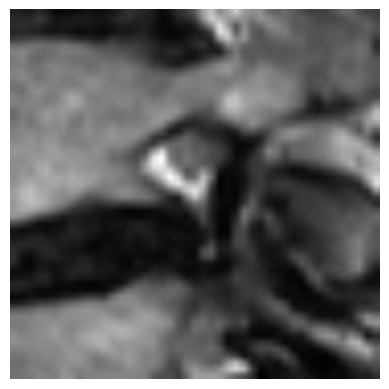

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from PIL import Image
d = pd.read_csv(C.METRICS / "preds_fusion.csv"); print(list(d.columns))
t = d[d["split"].eq("test")] if "split" in d else d[d["fold"].eq(-1)]
P = t[["p0", "p1", "p2", "p3"]].values; eg = (P * np.arange(4)).sum(1)
t = t.assign(exp_grade=eg, pred=np.digitize(eg, [0.72, 1.44, 2.36]), conf=P.max(1))
ex = t[(t.grade == 2) & (t.pred == 1)].sort_values("conf", ascending=False).iloc[0]
m = pd.read_csv(C.CACHE / "master.csv").merge(pd.read_csv(C.CACHE / "roi_index.csv"), on="foramen_id")
r = m[m.foramen_id == ex.foramen_id].iloc[0]
print(r.patient, r.level, r.side, "| true:", ex.grade, "| pred:", ex.pred, "| E[grade]:", round(ex.exp_grade, 2), "| p:", np.round(ex[["p0", "p1", "p2", "p3"]].values.astype(float), 3))
plt.imshow(Image.open(r.roi_path), cmap="gray"); plt.axis("off"); plt.savefig("example_crop.png", dpi=200, bbox_inches="tight")

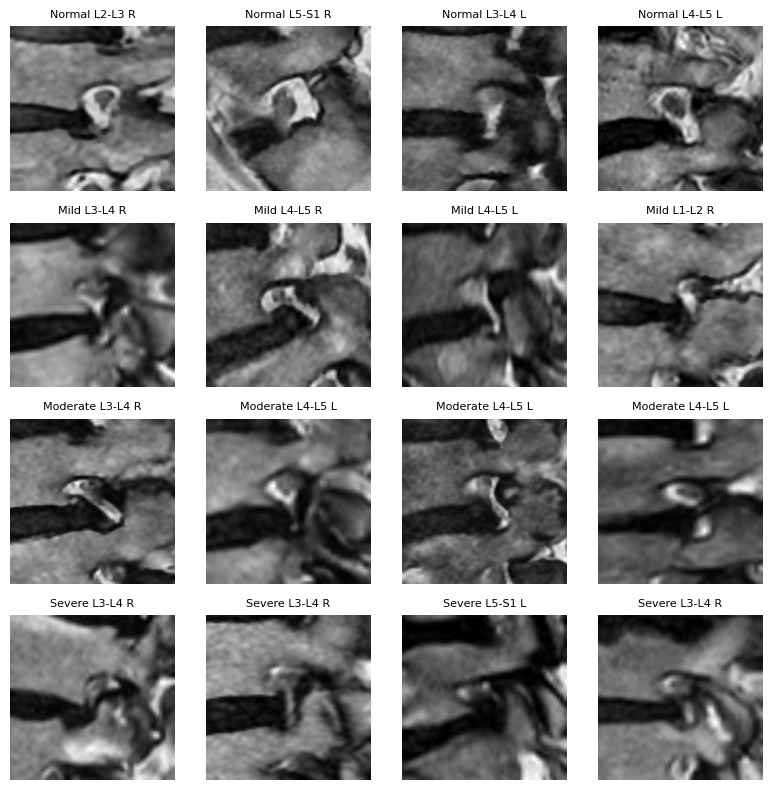

In [ ]:
#Figure 3.1 for the Mid Evaluation report
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
m, idx = pd.read_csv(C.CACHE / "master.csv"), pd.read_csv(C.CACHE / "roi_index.csv")
d = m.merge(idx, on="foramen_id")
fig, ax = plt.subplots(4, 4, figsize=(8, 8))
for g in range(4):
    for j, r in enumerate(d[d.grade == g].sample(4, random_state=0).itertuples()):
        ax[g, j].imshow(Image.open(r.roi_path), cmap="gray"); ax[g, j].axis("off")
        ax[g, j].set_title(f"{C.GRADES[g]} {r.level} {r.side}", fontsize=8)
plt.tight_layout(); plt.savefig("fig3_1_grade_grid.png", dpi=200, bbox_inches="tight"); plt.show()

**Pilot Run for Proposed XAI based Light Run**

In [2]:
#steup and restore full MRI slices
import os, glob, subprocess
if not glob.glob("/content/**/Foramina_Detection", recursive=True):
    z = glob.glob("/content/drive/MyDrive/LSS MRI AISSLab Dataset_V0.2.zip*")[0]
    subprocess.run(["unzip", "-q", "-o", z, "-d", "/content/lss_data"])
print(glob.glob("/content/**/Foramina_Detection", recursive=True)[:1])

['/content/lss_data/Foramina_Detection']


In [3]:
#Train one model and save its weights
src = open("train2.py").read()
old = "    final.load_state_dict(best_state)\n"
assert old in src
open("train2_save.py", "w").write(src.replace(old, old +
    "    torch.save(best_state, str(C.OUT / f'pilot_{cfg}_f{fold}_s{seed}.pt'))\n"))

21722

In [4]:
!python train2_save.py --config appearance --folds 0 --seeds 1337 --tag pilot_xai --recipe '{"backbone":"resnet18","img_size":128,"bs":48,"n_tta":1,"roi_dir":"rois","epochs":60,"patience":14}'

device=cuda tag=pilot_xai configs=['appearance'] folds=[0] seeds=[1337]
recipe={"anat_hidden": 64, "anat_out": 32, "backbone": "resnet18", "bright": 0.2, "bs": 48, "clip": 1.0, "contrast": 0.2, "drop": 0.3, "drop_path": 0.0, "ema": 0.995, "epochs": 60, "erase_p": 0.25, "freeze_blocks": 0, "img_size": 128, "loss_w": "none", "lr_backbone": 0.0002, "lr_head": 0.001, "n_tta": 1, "noise": 0.0, "patience": 14, "roi_dir": "rois", "rot_deg": 10.0, "sampler": "balanced", "scale": 0.1, "smooth": 0.0, "trans": 0.05, "warmup": 3, "wd": 0.0001}
n=2978 (dev=2398, test=580)
  RoiBank[rois] torch.Size([2978, 224, 224]) 149 MB
  cache 224px -> resampled on-device to img_size=128

model.safetensors: downloading bytes:   3% 1.26M/46.8M [00:00<00:22, 2.03MB/s]
model.safetensors: downloading bytes:  66% 30.8M/46.8M [00:00<00:00, 51.1MB/s, 1.95MB/s  ]
model.safetensors: reconstructing file:  17% 8.18M/46.8M [00:01<00:04, 8.35MB/s,  486kB/s  ]
model.safetensors: downloading bytes: 100% 44.0M/44.0M [00:01<00:

In [5]:
# RUnnig  the pilot
!cp "/content/drive/MyDrive/lss_study/pilot_xai.py" .
!python pilot_xai.py

test foramina: 580 | slices from: /content/lss_data/Foramina_Detection

=== Table E7: explanation check (test set, n=580) ===
   Crop   Model  Pointing game (Grad-CAM++)  Centre-only guess  Energy-in-box  Uniform baseline (box area)  QWK (argmax)
centred trained                       0.974                1.0          0.598                        0.310         0.771
centred  random                       0.326                1.0          0.293                        0.310         0.000
 offset trained                       0.281                0.0          0.102                        0.111         0.239
 offset  random                       0.453                0.0          0.123                        0.111         0.000

=== Offset crops, trained model, per grade ===
            n  pointing  energy
Normal    378     0.270   0.099
Mild      104     0.298   0.108
Moderate   53     0.340   0.115
Severe     45     0.267   0.101

Saved to /content/drive/MyDrive/lss_study/outputs/pilot_xai


**Running Pilot Joint Light Model**

In [2]:
#steup and restore full MRI slices
import os, glob, subprocess
if not glob.glob("/content/**/Foramina_Detection", recursive=True):
    z = glob.glob("/content/drive/MyDrive/LSS MRI AISSLab Dataset_V0.2.zip*")[0]
    subprocess.run(["unzip", "-q", "-o", z, "-d", "/content/lss_data"])
print(glob.glob("/content/**/Foramina_Detection", recursive=True)[:1])

['/content/lss_data/Foramina_Detection']


In [3]:
#Train one model and save its weights
src = open("train2.py").read()
old = "    final.load_state_dict(best_state)\n"
assert old in src
open("train2_save.py", "w").write(src.replace(old, old +
    "    torch.save(best_state, str(C.OUT / f'pilot_{cfg}_f{fold}_s{seed}.pt'))\n"))

21722

In [4]:
#Pilot Joint code here
!cp "/content/drive/MyDrive/lss_study/pilot_joint.py" .
!PILOT_EPOCHS=30 python pilot_joint.py

slices cached: 1473 in 5s | device=cuda
train 1892 | val 506 | test 580 foramina

model.safetensors: downloading bytes:  30% 4.19M/14.2M [00:01<00:02, 3.43MB/s]
model.safetensors: downloading bytes: 100% 13.5M/13.5M [00:01<00:00, 10.2MB/s, 1.30MB/s  ]
model.safetensors: reconstructing file: 100% 14.2M/14.2M [00:01<00:00, 10.7MB/s, 1.37MB/s  ]
Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
ep01 loss=2.805 val_QWK=0.362 val_point_in_box=0.449 (11s)
ep02 loss=1.968 val_QWK=0.468 val_point_in_box=0.476 (8s)
ep03 loss=1.890 val_QWK=0.491 val_point_in_box=0.518 (8s)
ep04 loss=1.786 val_QWK=0.540 val_point_in_box=0.551 (9s)
ep05 loss=1.707 val_QWK=0.528 val_point_in_box=0.561 (9s)
ep06 loss=1.690 val_QWK=0.563 val_point_in_box=0.587 (8s)
ep07 loss=1.627 val_QWK=0.577 val_point_in_box=0.617 (8s)
ep08 lo